# HW1 – Part 2: Plotting and data visualization
**Soft Matter Simulation – Homework 1**

Calculations from section **5. Plotting and Data Visualization** of the MolSSI lesson
(https://education.molssi.org/python_scripting_cms/), using the data file `distance_data_headers.csv`
from the course repository (`practical_session_1/data`).

The file contains, for each simulation frame, four interatomic distances (in Å) from a molecular dynamics trajectory:
`THR4_ATP`, `THR4_ASP`, `TYR6_ATP`, `TYR6_ASP`.

## 0. Load the data
The file is read from a local `data/` folder if present; otherwise it is downloaded from the course repository (so the notebook also runs in Google Colab).

In [1]:
import os
import urllib.request
import numpy

distance_file = os.path.join('data', 'distance_data_headers.csv')
if not os.path.exists(distance_file):
    os.makedirs('data', exist_ok=True)
    url = 'https://raw.githubusercontent.com/jfaraudo/Softmatter_simulation_Introductory_course/main/practical_session_1/data/distance_data_headers.csv'
    urllib.request.urlretrieve(url, distance_file)

distances = numpy.genfromtxt(fname=distance_file, delimiter=',', dtype='unicode')
headers = distances[0]
data = distances[1:]
# Note: the lesson uses numpy.float, which was removed in NumPy 1.24; the built-in float is equivalent.
data = data.astype(float)

print(headers)
print(data.shape)

['Frame' 'THR4_ATP' 'THR4_ASP' 'TYR6_ATP' 'TYR6_ASP']
(10000, 5)


In [2]:
# Folder for the saved figures
os.makedirs('figures', exist_ok=True)

## 1. First plot

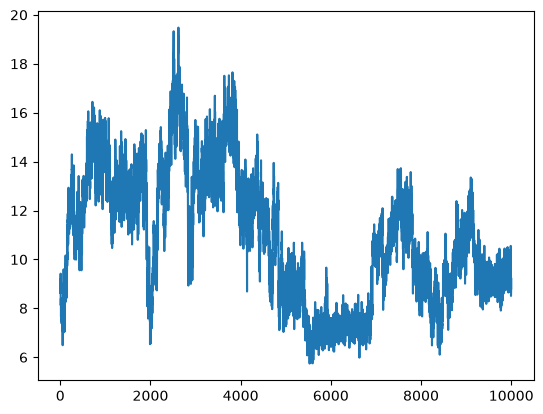

In [3]:
import matplotlib.pyplot as plt

plt.figure()     # initialise a new figure
plt.plot(data[:, 1])
plt.show()

## 2. Labels, legend and saving the figure

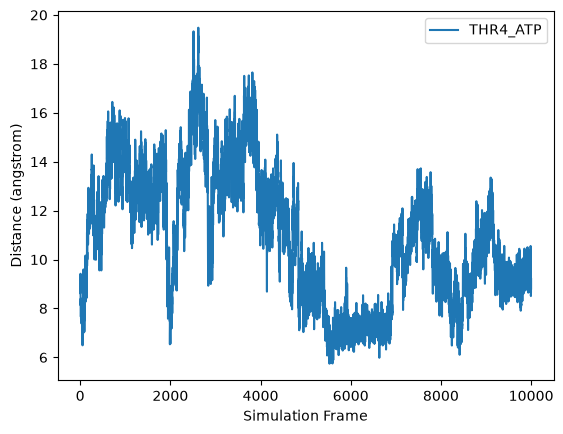

In [4]:
sample = headers[1]

plt.figure()
plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
fig_1 = plt.plot(data[:, 1], label=sample)
plt.legend()

plt.savefig(os.path.join('figures', f'{sample}.png'))
plt.show()

## 3. Higher resolution (`dpi=300`)

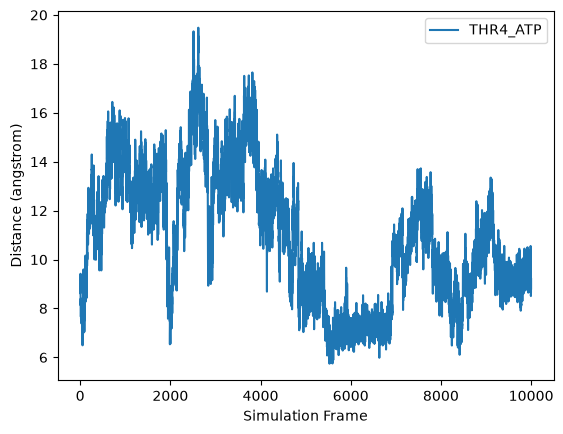

In [5]:
plt.figure()
plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
plt.plot(data[:, 1], label=sample)
plt.legend()

plt.savefig(os.path.join('figures', f'{sample}_300dpi.png'), dpi=300)
plt.show()

## 4. More than one data set on the same plot

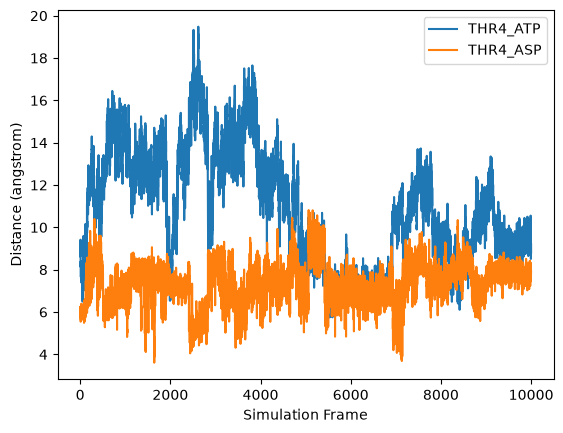

In [6]:
plt.figure()
plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
plt.plot(data[:, 1], label=headers[1])
plt.plot(data[:, 2], label=headers[2])
plt.legend()
plt.savefig(os.path.join('figures', 'two_samples.png'))
plt.show()

All samples with a `for` loop over the columns:

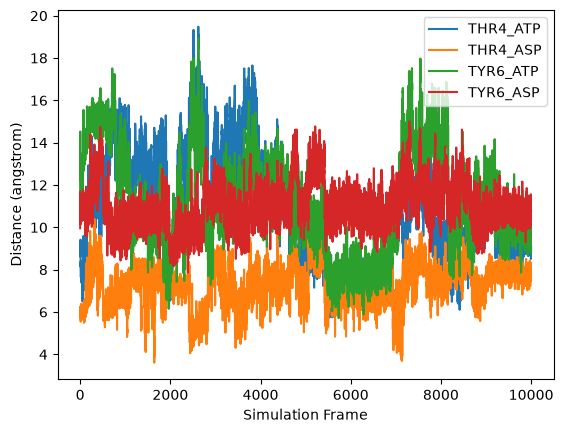

In [7]:
plt.figure()
for col in range(1, len(headers)):
    plt.plot(data[:, col], label=headers[col])
plt.legend()

plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
plt.savefig(os.path.join('figures', 'all_samples.png'))
plt.show()

## 5. Exercise: one plot per sample
Move `plt.figure()` and `plt.savefig()` inside the loop; each image is saved as `sample_name.png`.

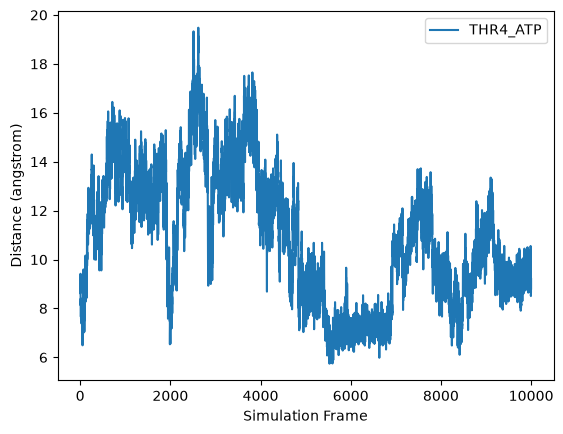

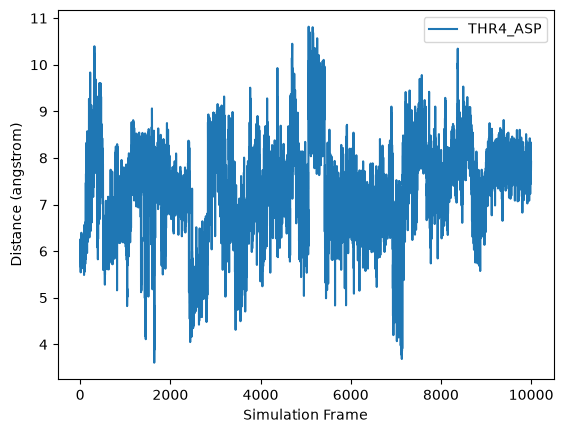

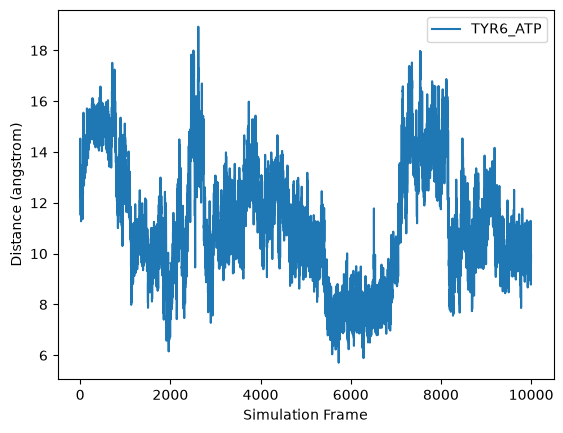

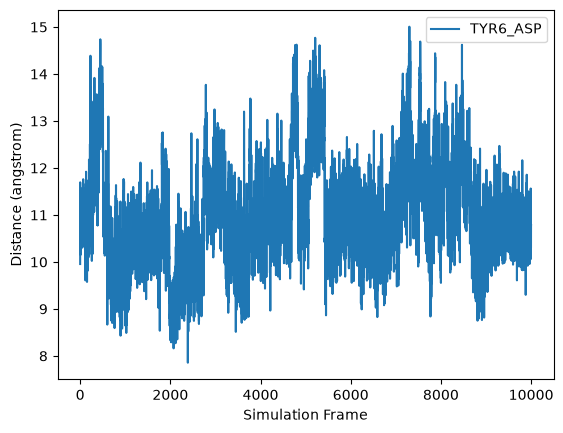

In [8]:
for col in range(1, len(headers)):
    plt.figure()
    sample = headers[col]

    plt.plot(data[:, col], label=sample)
    plt.legend()
    plt.xlabel('Simulation Frame')
    plt.ylabel('Distance (angstrom)')

    plt.savefig(os.path.join('figures', f'{sample}.png'))
    plt.show()

## 6. Same y-axis range for all plots
**Check your understanding:** a sensible range is given by the minimum and maximum distance in the whole data set.

In [9]:
data_min = numpy.min(data[:, 1:])
data_max = numpy.max(data[:, 1:])
print(f'Minimum distance: {data_min:.4f} Å')
print(f'Maximum distance: {data_max:.4f} Å')

Minimum distance: 3.6061 Å
Maximum distance: 19.4800 Å


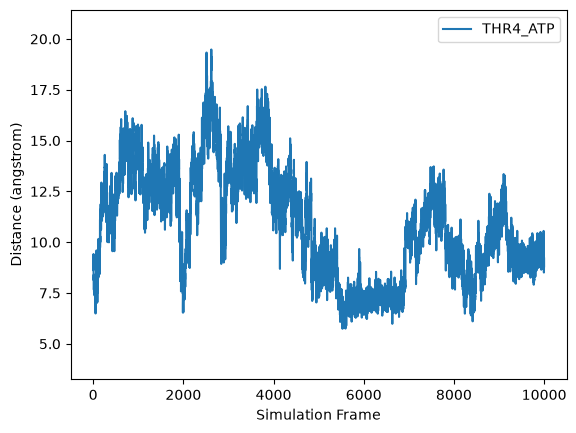

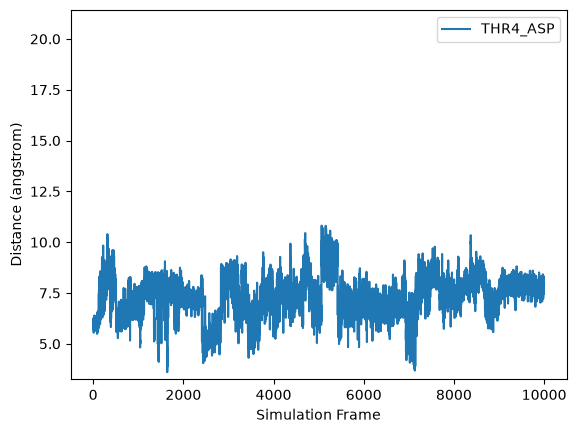

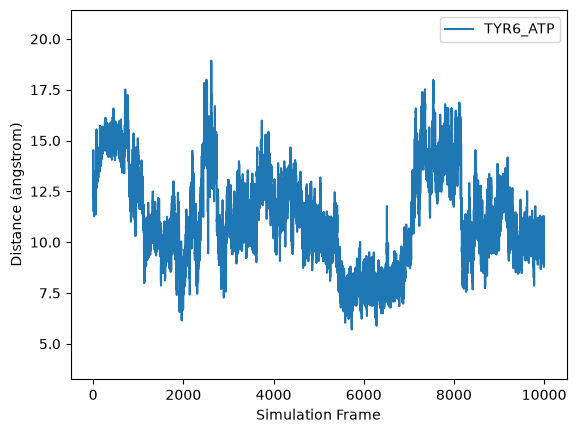

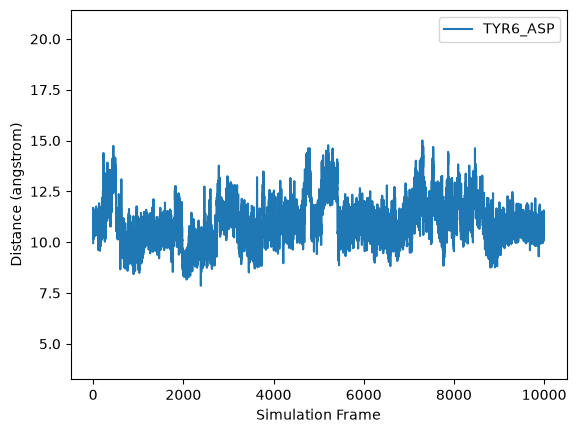

In [10]:
# Add 10 % margin
data_min = numpy.min(data[:, 1:]) * 0.9
data_max = numpy.max(data[:, 1:]) * 1.1

for col in range(1, len(headers)):
    plt.figure()
    sample = headers[col]

    plt.plot(data[:, col], label=sample)
    plt.ylim(data_min, data_max)
    plt.legend()
    plt.xlabel('Simulation Frame')
    plt.ylabel('Distance (angstrom)')

    plt.savefig(os.path.join('figures', f'{sample}_samey.png'))
    plt.show()

## 7. Plotting with explicit `x` and `y`
Using the `Frame` column as `x` gives the same curve:

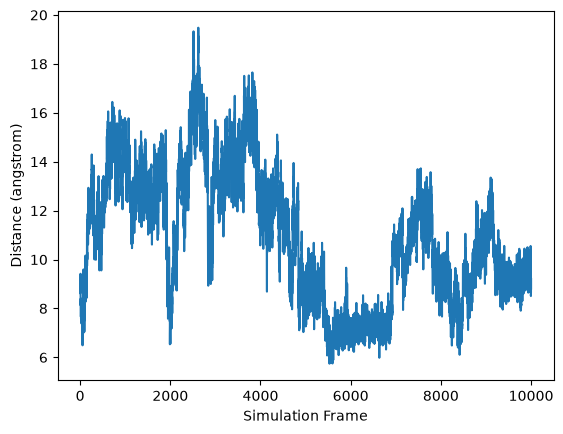

In [11]:
plt.figure()
plt.plot(data[:, 0], data[:, 1])
plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
plt.show()

Slicing with a step, `array[start:stop:interval]`: every other row up to row 10.

In [12]:
print(data[0:10:2, :])

[[ 1.      8.9542  5.8024 11.5478  9.9557]
 [ 3.      9.0066  6.0637 13.0924 11.3043]
 [ 5.      9.1294  5.9365 13.5321 10.6279]
 [ 7.      8.8657  5.9186 12.9312 10.2176]
 [ 9.      9.4184  6.1993 13.2614 10.366 ]]


**Check your understanding:** every 100th point of the first column.

In [13]:
incr_100 = data[0::100, 0]
print(incr_100[:10], '...', len(incr_100), 'points')

[  1. 101. 201. 301. 401. 501. 601. 701. 801. 901.] ... 100 points


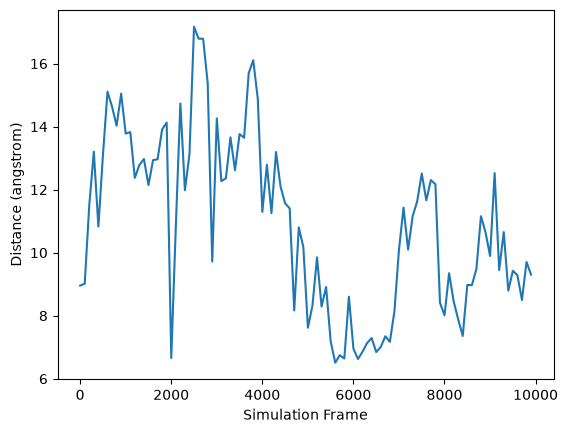

In [14]:
plt.figure()
plt.plot(data[0::100, 0], data[0::100, 1])
plt.xlabel('Simulation Frame')
plt.ylabel('Distance (angstrom)')
plt.show()

## 8. Customising the appearance

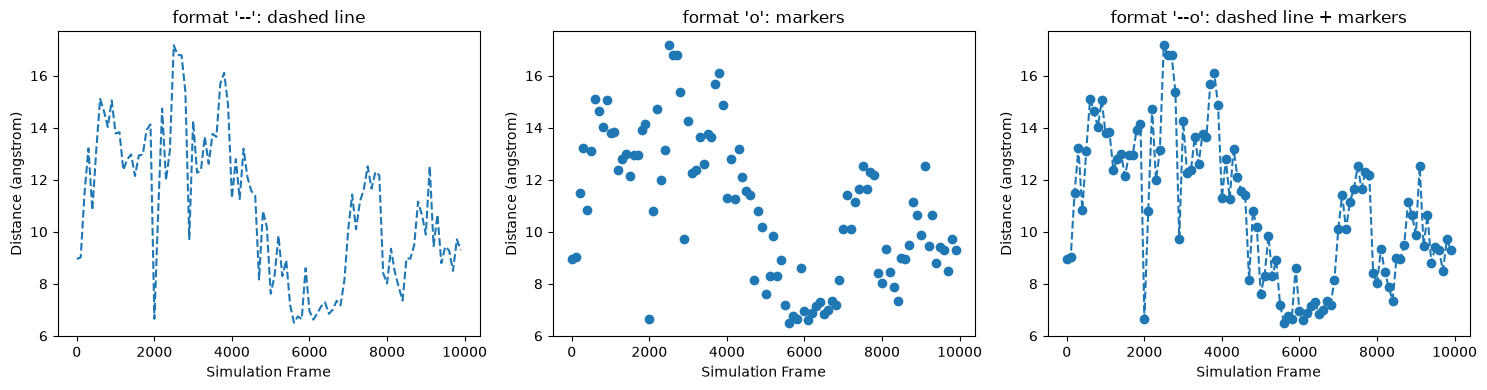

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, fmt, title in zip(axs, ['--', 'o', '--o'], ['dashed line', 'markers', 'dashed line + markers']):
    ax.plot(data[0::100, 0], data[0::100, 1], fmt)
    ax.set_title(f"format '{fmt}': {title}")
    ax.set_xlabel('Simulation Frame')
    ax.set_ylabel('Distance (angstrom)')
plt.tight_layout()
plt.show()

**Check your understanding:** black dashed line with circular markers.
(The lesson's solution uses `':ok'`; strictly, `':'` is a *dotted* line and `'--'` is *dashed*, so both are shown.)

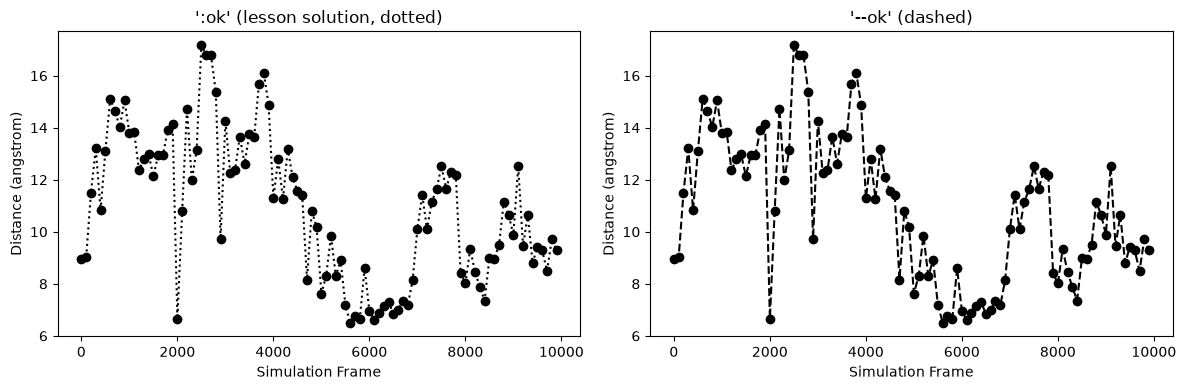

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(data[0::100, 0], data[0::100, 1], ':ok')
axs[0].set_title("':ok' (lesson solution, dotted)")
axs[1].plot(data[0::100, 0], data[0::100, 1], '--ok')
axs[1].set_title("'--ok' (dashed)")
for ax in axs:
    ax.set_xlabel('Simulation Frame')
    ax.set_ylabel('Distance (angstrom)')
plt.tight_layout()
plt.show()

## 9. Several plots in one figure: `subplots`

In [17]:
fig, ax = plt.subplots(len(headers) - 1, 1)
print(ax.shape)
plt.close(fig)

fig2, ax2 = plt.subplots(2, 2)
print(ax2.shape)
plt.close(fig2)

(4,)
(2, 2)


**Check your understanding:** use a `for` loop to add all the data to the figure.

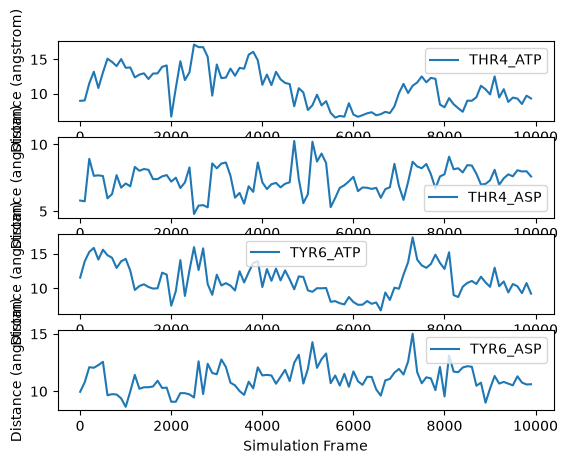

In [18]:
fig, ax = plt.subplots(len(headers) - 1, 1)

for col in range(1, len(headers)):
    sample = headers[col]

    ax[col - 1].plot(data[0::100, 0], data[0::100, col], label=sample)
    ax[col - 1].set_xlabel('Simulation Frame')
    ax[col - 1].set_ylabel('Distance (angstrom)')
    ax[col - 1].legend()
plt.show()

### Improving the figure
Larger size (`figsize`) and a common y axis (`sharey=True`).

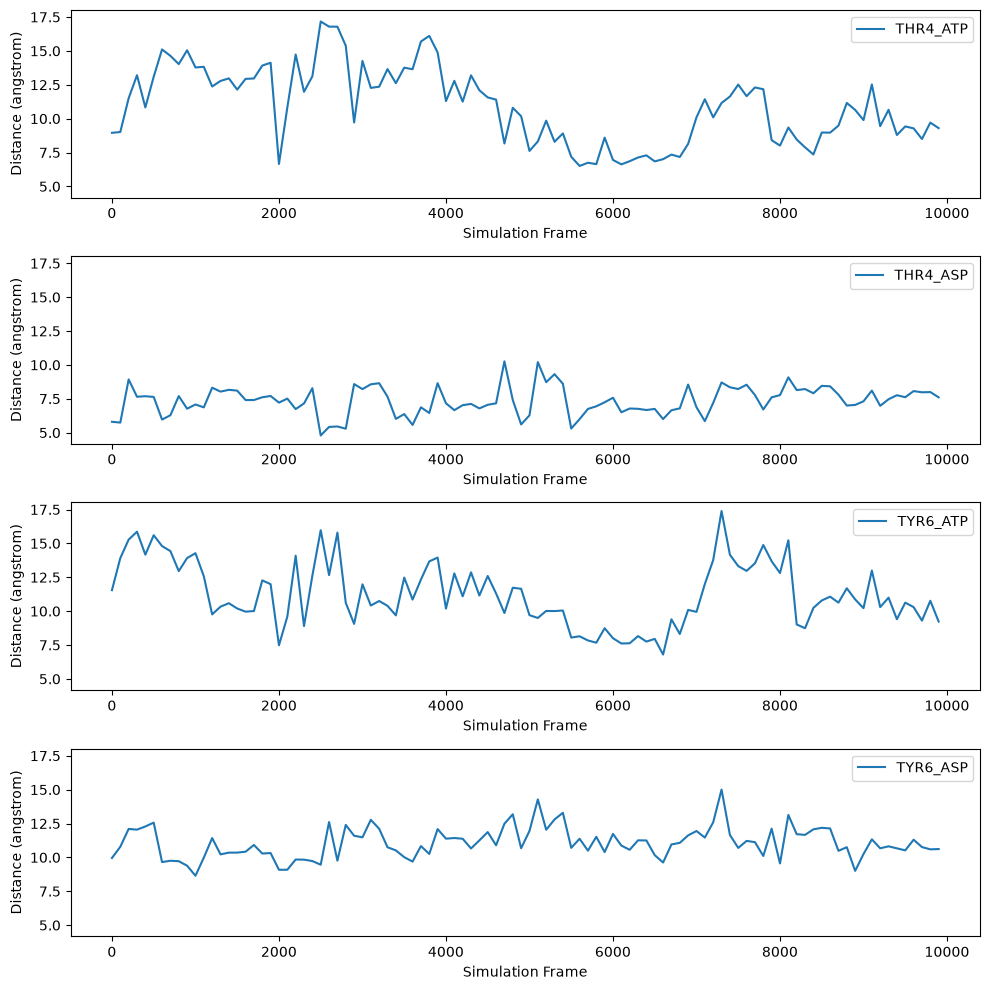

In [19]:
fig, ax = plt.subplots(len(headers) - 1, 1, figsize=(10, 10), sharey=True)

for col in range(1, len(headers)):
    sample = headers[col]

    ax[col - 1].plot(data[0::100, 0], data[0::100, col], label=sample)
    ax[col - 1].set_xlabel('Simulation Frame')
    ax[col - 1].set_ylabel('Distance (angstrom)')
    ax[col - 1].legend()

plt.tight_layout()
fig.savefig(os.path.join('figures', 'subplots.png'), dpi=300)
plt.show()